# Savdo tahlili va mijozlar sonini bashorat qilish

**Ma'lumot:** `data/sales.csv`. Oshxonaning 900 kunlik savdosi (2023-01-01 → 2025-06-18): mijozlar, guruch, salat, tushum, ob-havo, bayramlar, aksiyalar.

**3 ta savolga javob beramiz:**
1. Mijozlar sonini nima belgilaydi?
2. Ertangi mijozlar sonini qanchalik aniq bashorat qila olamiz? (sklearn va Keras/TensorFlow)
3. **95% aniqlikka chiqa olamizmi?**

**Target:** `customers`. Guruch, salat va tushum mijozlar soniga deyarli to'liq bog'liq, shuning uchun mijozlar sonini bilsak, qolgani oddiy ko'paytirish bilan topiladi (6-bo'limga qarang).

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # TensorFlow'ning texnik loglarini o'chirish

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

import tensorflow as tf
import keras

df = pd.read_csv("../data/sales.csv", parse_dates=["date"])
bool_cols = df.select_dtypes("bool").columns
df[bool_cols] = df[bool_cols].astype(int)

print(df.shape, "| bo'sh qiymatlar:", df.isna().sum().sum(), "| TensorFlow", tf.__version__, "| Keras", keras.__version__)
df.head(3)

(900, 21) | bo'sh qiymatlar: 0 | TensorFlow 2.21.0 | Keras 3.15.1


,date,customers,rice_kg,salad_count,revenue_uzs,temp_c,humidity,wind,rain,snow,...,is_weekend,month,season,is_holiday,ramadan,eid,salary_week,promotion,local_event,football_match
0,2023-01-01,194,44.6,121,10698182,0.4,74.9,5.7,1,0,...,1,1,winter,1,0,0,0,0,0,0
1,2023-01-02,116,27.1,69,6270691,2.8,85.1,1.6,1,0,...,0,1,winter,0,0,0,0,0,0,0
2,2023-01-03,173,40.2,103,9654998,-1.7,89.2,4.4,0,0,...,0,1,winter,0,0,0,1,0,0,0


## 1. Asosiy manzara (EDA)

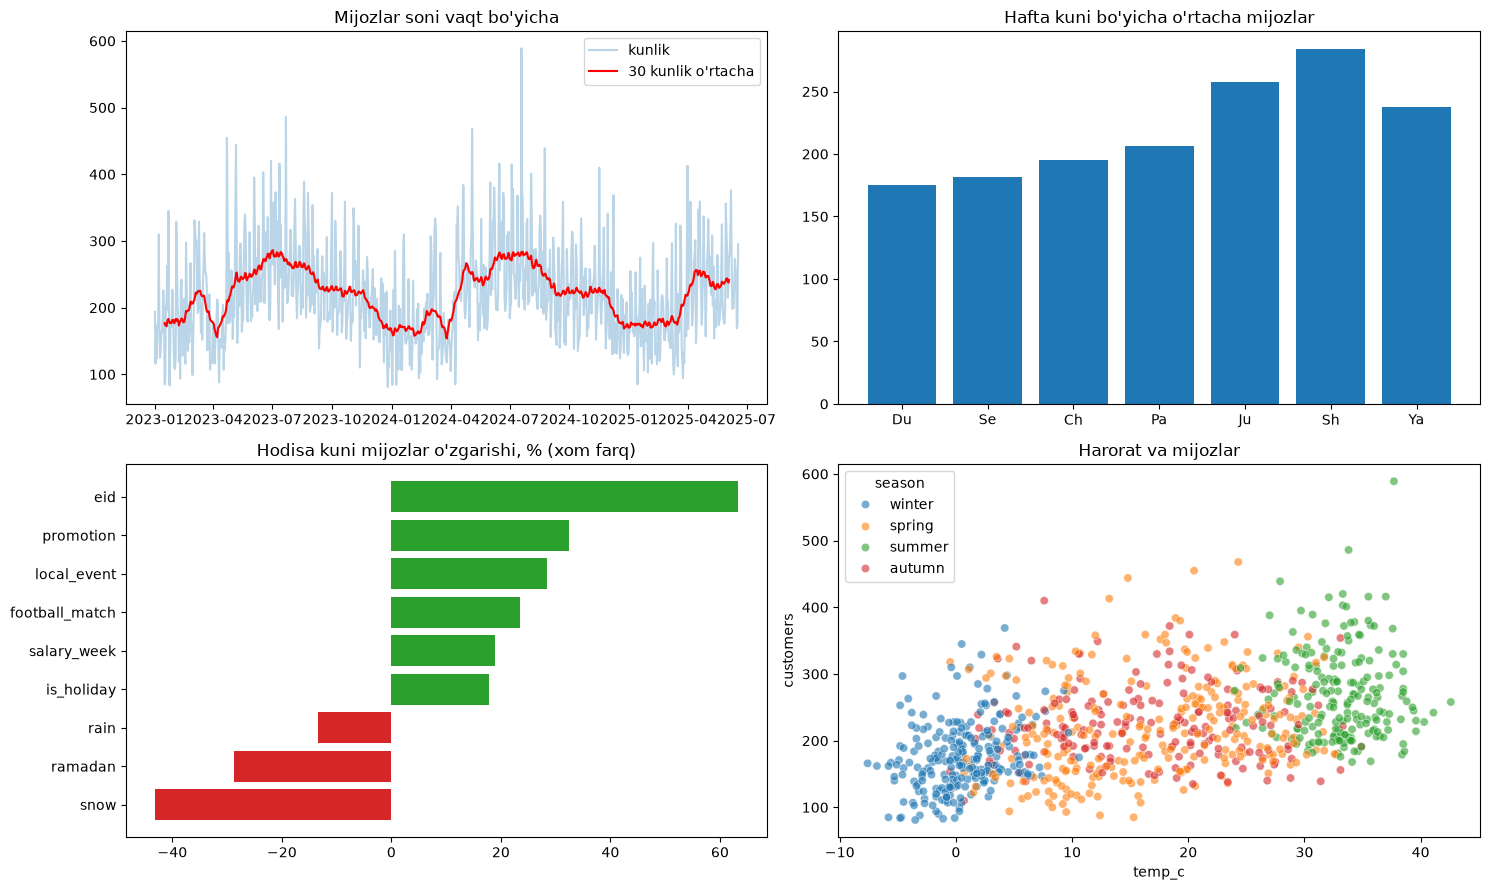

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# 1) Vaqt bo'yicha: kunlik va 30 kunlik o'rtacha
s = df.set_index("date")["customers"]
ax[0, 0].plot(s, alpha=0.3, label="kunlik")
ax[0, 0].plot(s.rolling(30, center=True).mean(), color="red", label="30 kunlik o'rtacha")
ax[0, 0].set_title("Mijozlar soni vaqt bo'yicha"); ax[0, 0].legend()

# 2) Hafta kunlari
days = ["Du", "Se", "Ch", "Pa", "Ju", "Sh", "Ya"]
wk = df.groupby("weekday")["customers"].mean()
ax[0, 1].bar(days, wk); ax[0, 1].set_title("Hafta kuni bo'yicha o'rtacha mijozlar")

# 3) Hodisalar ta'siri: hodisa bo'lgan kun va bo'lmagan kun farqi (%)
events = ["eid", "promotion", "local_event", "football_match", "salary_week",
          "is_holiday", "rain", "ramadan", "snow"]
lift = pd.Series({e: (df[df[e] == 1].customers.mean() / df[df[e] == 0].customers.mean() - 1) * 100
                  for e in events}).sort_values()
ax[1, 0].barh(lift.index, lift, color=np.where(lift > 0, "tab:green", "tab:red"))
ax[1, 0].set_title("Hodisa kuni mijozlar o'zgarishi, % (xom farq)")

# 4) Harorat
sns.scatterplot(data=df, x="temp_c", y="customers", hue="season", alpha=0.6, ax=ax[1, 1])
ax[1, 1].set_title("Harorat va mijozlar")

plt.tight_layout(); plt.show()

In [3]:
# Bitta mijozga to'g'ri keladigan sarf: deyarli o'zgarmas
per_cust = pd.DataFrame({
    "guruch, kg":  df.rice_kg / df.customers,
    "salat, dona": df.salad_count / df.customers,
    "tushum, so'm": df.revenue_uzs / df.customers,
}).describe().loc[["mean", "std"]].round(3)
per_cust

,"guruch, kg","salat, dona","tushum, so'm"
mean,0.220,0.599,55906.737
std,0.011,0.030,2479.505


**Xulosalar:**
- Talab **haftalik ritmga** bo'ysunadi: juma va shanba eng gavjum kunlar, dushanbada esa mijoz eng kam.
- **Hayit** kunlari mijozlar keskin ko'payadi. **Aksiya**, mahalliy tadbir va **oylik haftasi** ham talabni sezilarli oshiradi.
- **Ramazon** va **qor** talabni eng ko'p tushiradi. Iliq kunlarda mijoz ko'proq bo'ladi.
- Bitta mijozga ~0.22 kg guruch, ~0.6 ta salat va ~56 000 so'm tushum to'g'ri keladi, tebranish atigi ~5%. Demak, **asosiy savol mijozlar sonini bilish**, qolgani shundan hisoblanadi.

## 2. ⚠️ Tuzoq: data leakage, ya'ni "soxta 98%"

`rice_kg`, `salad_count` va `revenue_uzs` mijozlar soni bilan **0.98–0.99** korrelyatsiyaga ega. Ularni modelga qo'shsak, natija ajoyib chiqadi:

In [4]:
split = int(len(df) * 0.8)            # vaqt bo'yicha: birinchi 80% train, oxirgi 20% test
train, test = df.iloc[:split], df.iloc[split:]

leak = ["rice_kg", "salad_count", "revenue_uzs"]
p = LinearRegression().fit(train[leak], train.customers).predict(test[leak])
print(f"Leakage bilan 'aniqlik': {100 - mean_absolute_percentage_error(test.customers, p) * 100:.1f}%")

Leakage bilan 'aniqlik': 97.5%


**Lekin bu aldov.** Kun boshida, ya'ni bashorat kerak bo'lgan paytda, bugun qancha guruch sarflanishi va qancha tushum bo'lishi **hali noma'lum**. Bular mijozlar sonining *natijasi*, sababi emas. Bunday model real hayotda ishlamaydi.

**Qoida:** modelga faqat bashorat paytida **oldindan ma'lum** bo'lgan ma'lumotni beramiz: sana, ob-havo prognozi, bayram, aksiya rejasi, tadbirlar.

## 3. Halol model: sklearn

In [5]:
features = ["weekday", "month", "temp_c", "humidity", "wind", "rain", "snow", "is_weekend",
            "is_holiday", "ramadan", "eid", "salary_week", "promotion", "local_event", "football_match"]

def add_features(d):
    d = d[features].copy()
    d["temp_sq"] = d.temp_c ** 2       # juda sovuq va juda issiq kunlarda ta'sir boshqacha bo'lishi mumkin
    return d

X_train, X_test = add_features(train), add_features(test)
y_train, y_test = train.customers, test.customers

def make_preprocessor():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["weekday", "month"])],
                             remainder=StandardScaler())

results = {}
def evaluate(name, pred):
    ape = np.abs(pred - y_test) / y_test
    results[name] = {"MAE (mijoz)": round(mean_absolute_error(y_test, pred), 1),
                     "MAPE %": round(ape.mean() * 100, 2),
                     "Aniqlik % (100−MAPE)": round(100 - ape.mean() * 100, 1),
                     "R²": round(r2_score(y_test, pred), 3),
                     "±10% ichida, kunlar %": round((ape <= 0.10).mean() * 100)}

print("Train:", train.date.min().date(), "→", train.date.max().date(), f"({len(train)} kun)")
print("Test: ", test.date.min().date(),  "→", test.date.max().date(),  f"({len(test)} kun)")

Train: 2023-01-01 → 2024-12-20 (720 kun)
Test:  2024-12-21 → 2025-06-18 (180 kun)


📖 **Muhim tafsilotlar:**
- **Vaqt bo'yicha bo'lish:** `train_test_split` aralashtirib yuboradi va model "kelajakdan" o'rganib qoladi. Real hayotda biz o'tmish asosida kelajakni bashorat qilamiz, shuning uchun test aynan **oxirgi 6 oy**.
- **Log target:** ta'sirlar *foizda* ishlaydi. Masalan, aksiya +10% beradi, bu +25 mijoz degani emas. `log(customers)` bashorat qilinsa, chiziqli model ham bu ko'paytma ta'sirlarni to'g'ri ushlaydi.
- **Baseline:** "o'tgan haftaning shu kuni qancha bo'lsa, bugun ham shuncha bo'ladi".

In [6]:
evaluate("Baseline: 7 kun oldingi qiymat", df.customers.shift(7).iloc[split:].values)

ridge = make_pipeline(make_preprocessor(), Ridge(alpha=1)).fit(X_train, y_train)
evaluate("Ridge", ridge.predict(X_test))

ridge_log = make_pipeline(make_preprocessor(), Ridge(alpha=1)).fit(X_train, np.log(y_train))
evaluate("Ridge (log target)", np.exp(ridge_log.predict(X_test)))

gb_log = make_pipeline(make_preprocessor(), GradientBoostingRegressor(
    n_estimators=600, learning_rate=0.02, max_depth=2, random_state=42)).fit(X_train, np.log(y_train))
evaluate("Gradient Boosting (log target)", np.exp(gb_log.predict(X_test)))

pd.DataFrame(results).T

,MAE (mijoz),MAPE %,Aniqlik % (100−MAPE),R²,"±10% ichida, kunlar %"
Baseline: 7 kun oldingi qiymat,52.2,26.16,73.8,-0.144,24.0
Ridge,17.4,9.36,90.6,0.880,64.0
Ridge (log target),14.3,7.09,92.9,0.922,79.0
Gradient Boosting (log target),19.2,9.11,90.9,0.847,63.0


## 4. Keras / TensorFlow

Ikki xil neyron tarmoqni sinaymiz:
- **Keras linear:** bitta `Dense(1)` qatlami. Bu oddiy chiziqli regressiya, faqat **gradient descent** bilan o'qitiladi. 01-notebookdagi `train` funksiyasining TensorFlow'dagi ko'rinishi.
- **Keras MLP:** yashirin qatlam (`Dense(32, relu)`) va `Dropout`. U chiziqli bo'lmagan bog'liqliklarni ham o'rgana oladi.

Ikkalasida ham **EarlyStopping** ishlatiladi: validation loss 30 epoch davomida yaxshilanmasa, o'qitish to'xtaydi va eng yaxshi weight'lar tiklanadi. Neyron tarmoqlarda bu overfitting'ga qarshi asosiy himoya.

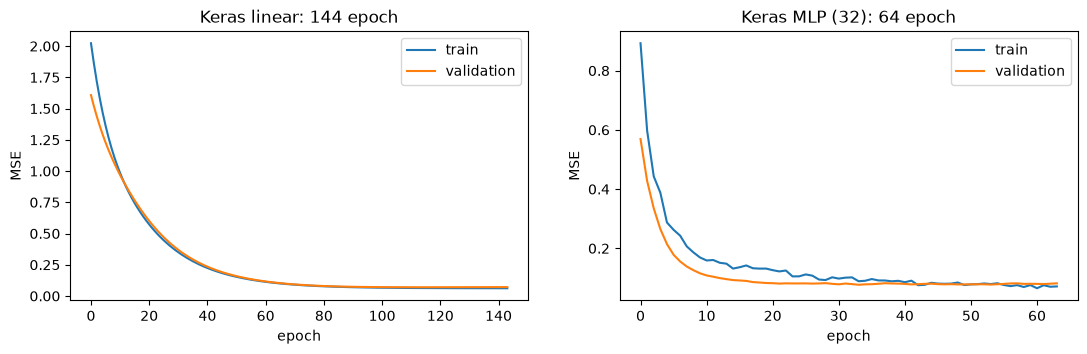

,MAE (mijoz),MAPE %,Aniqlik % (100−MAPE),R²,"±10% ichida, kunlar %"
Ridge (log target),14.3,7.09,92.9,0.922,79.0
Keras linear,15.0,7.43,92.6,0.914,73.0
Keras MLP (32),16.4,7.86,92.1,0.889,72.0
Gradient Boosting (log target),19.2,9.11,90.9,0.847,63.0
Ridge,17.4,9.36,90.6,0.880,64.0
Baseline: 7 kun oldingi qiymat,52.2,26.16,73.8,-0.144,24.0


In [7]:
prep = make_preprocessor().fit(X_train)
Xtr = prep.transform(X_train).astype("float32")
Xte = prep.transform(X_test).astype("float32")

# Target'ni ham log + standartlashtirish: neyron tarmoq kichik sonlar bilan barqarorroq o'qiydi
ytr_log = np.log(y_train.values)
mu, sd = ytr_log.mean(), ytr_log.std()
ytr_scaled = ((ytr_log - mu) / sd).astype("float32")

def build(hidden):
    layers = [keras.Input(shape=(Xtr.shape[1],))]
    for units in hidden:
        layers += [keras.layers.Dense(units, activation="relu"), keras.layers.Dropout(0.1)]
    layers += [keras.layers.Dense(1)]
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model

histories = {}
for name, hidden in [("Keras linear", []), ("Keras MLP (32)", [32])]:
    keras.utils.set_random_seed(42)
    model = build(hidden)
    h = model.fit(Xtr, ytr_scaled, validation_split=0.2,   # train'ning oxirgi 20% i validation
                  epochs=500, batch_size=32, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
    histories[name] = h.history
    evaluate(name, np.exp(model.predict(Xte, verbose=0).ravel() * sd + mu))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for a, (name, hist) in zip(ax, histories.items()):
    a.plot(hist["loss"], label="train"); a.plot(hist["val_loss"], label="validation")
    a.set_title(f"{name}: {len(hist['loss'])} epoch"); a.set_xlabel("epoch"); a.set_ylabel("MSE"); a.legend()
plt.show()

pd.DataFrame(results).T.sort_values("MAPE %")

**Nega neyron tarmoq daraxtlardan va Ridge'dan yaxshiroq emas?**
- Ma'lumot atigi ~700 kunlik train. Neyron tarmoqlar o'n minglab qatorda o'zini ko'rsatadi, kichik jadvalli ma'lumotda esa odatda chiziqli modellar yoki boosting yutadi.
- Bu yerda bog'liqlik o'zi deyarli **ko'paytma-chiziqli** (log'dan keyin chiziqli). Shuning uchun murakkab model qo'shimcha naqsh topmaydi, faqat shovqinni yodlab olish xavfi oshadi.
- **Keras linear ≈ Ridge (log):** bir xil model, bir xil natija. Farqi faqat yechish usulida: formula yoki gradient descent.

## 5. 95% aniqlikka chiqa olamizmi?

Avval "aniqlik" nimani anglatishini kelishib olamiz. Regressiyada "accuracy" yo'q, shuning uchun **Aniqlik = 100% − MAPE** deb olamiz. 95% aniqlik degani: o'rtacha xato ≤ 5%, ya'ni 200 mijozlik kunda ±10 mijoz.

Buni tekshirish uchun **qoldiq xatoni** (residual) tahlil qilamiz. Train va test'dagi xato bir xil bo'lsa, model overfitting ham, underfitting ham qilmayapti. Demak qolgan xato bu **tasodifiy shovqin**, ya'ni mavjud feature'lar bilan tushuntirib bo'lmaydigan qism.

Train'dagi o'rtacha xato (MAPE): 6.4%   ← model o'zi o'rgangan ma'lumotda ham!
Test'dagi o'rtacha xato (MAPE):  7.1%
Kunlik tasodifiy tebranish (std): ±8.1%


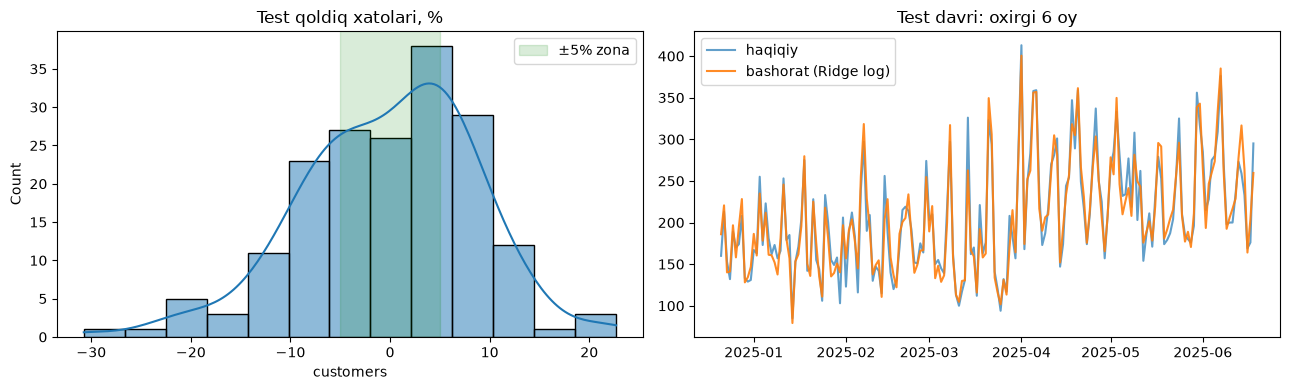

In [8]:
res_train = np.log(y_train) - ridge_log.predict(X_train)
res_test  = np.log(y_test)  - ridge_log.predict(X_test)

print(f"Train'dagi o'rtacha xato (MAPE): {np.mean(np.abs(np.expm1(-res_train))) * 100:.1f}%   "
      f"← model o'zi o'rgangan ma'lumotda ham!")
print(f"Test'dagi o'rtacha xato (MAPE):  {np.mean(np.abs(np.expm1(-res_test))) * 100:.1f}%")
print(f"Kunlik tasodifiy tebranish (std): ±{res_train.std() * 100:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(res_test * 100, kde=True, ax=ax[0])
ax[0].axvspan(-5, 5, color="green", alpha=0.15, label="±5% zona")
ax[0].set_title("Test qoldiq xatolari, %"); ax[0].legend()

pred = np.exp(ridge_log.predict(X_test))
ax[1].plot(test.date, y_test, label="haqiqiy", alpha=0.7)
ax[1].plot(test.date, pred, label="bashorat (Ridge log)", alpha=0.9)
ax[1].set_title("Test davri: oxirgi 6 oy"); ax[1].legend()
plt.tight_layout(); plt.show()

### Javob: yo'q, mavjud ma'lumot bilan halol 95% ga chiqib bo'lmaydi

- Eng yaxshi halol model **~93% aniqlik** (MAPE ≈ 7%) va **R² ≈ 0.92** beradi.
- Model **o'zi o'rgangan train ma'lumotida ham** ~6.5% xato qiladi. Bu xato model kuchsizligidan emas: bu ma'lumotning ichidagi **~8% kunlik tasodifiy tebranish**. Sana, ob-havo va hodisalar uni tushuntira olmaydi. Uni hech qanday model, na boosting, na Keras, yo'q qila olmaydi.
- 98% faqat **leakage** bilan chiqadi va u real hayotda ishlamaydi (2-bo'lim).

**95% ga yaqinlashish uchun nima kerak?** Yangi *ma'lumot*, yangi model emas:
- oldindan qilingan buyurtmalar va bron soni;
- atrofdagi tadbirlar haqida aniqroq ma'lumot: ishtirokchilar soni, vaqti;
- kunduzgi va kechki tushlik smenalari bo'yicha alohida ma'lumot;
- ko'proq tarix: 2.5 yil emas, 5+ yil.

**Yaxshi xabar:** biznes uchun aniq son emas, **ishonchli oraliq** muhimroq. Uni hisoblaymiz.

## 6. Amaliy natija: ertangi kun uchun reja

In [9]:
# 95% ishonch oralig'i: test'dagi qoldiqlarning 2.5% va 97.5% kvantillari
lo_q, hi_q = np.quantile(res_test, [0.025, 0.975])
print(f"95% oraliq: bashorat × [{np.exp(lo_q):.2f} … {np.exp(hi_q):.2f}]")

# Misol: oddiy iyun jumasi, +28°C, aksiya va tadbir yo'q
tomorrow = pd.DataFrame([{
    "weekday": 4, "month": 6, "temp_c": 28, "humidity": 40, "wind": 3, "rain": 0, "snow": 0,
    "is_weekend": 0, "is_holiday": 0, "ramadan": 0, "eid": 0, "salary_week": 0,
    "promotion": 0, "local_event": 0, "football_match": 0}])
c = np.exp(ridge_log.predict(add_features(tomorrow)))[0]
lo, hi = c * np.exp(lo_q), c * np.exp(hi_q)

rice, salad, rev = (df.rice_kg / df.customers).mean(), (df.salad_count / df.customers).mean(), (df.revenue_uzs / df.customers).mean()
plan = pd.DataFrame({
    "bashorat":     [round(c), round(c * rice, 1), round(c * salad), f"{c * rev:,.0f}"],
    "95% oraliq":   [f"{lo:.0f} – {hi:.0f}", f"{lo * rice:.1f} – {hi * rice:.1f}",
                     f"{lo * salad:.0f} – {hi * salad:.0f}", f"{lo * rev:,.0f} – {hi * rev:,.0f}"],
}, index=["mijozlar", "guruch, kg", "salat, dona", "tushum, so'm"])
plan

95% oraliq: bashorat × [0.82 … 1.15]


,bashorat,95% oraliq
mijozlar,279,229 – 321
"guruch, kg",61.4,50.5 – 70.6
"salat, dona",167,137 – 192
"tushum, so'm","15,613,453","12,819,200 – 17,940,162"


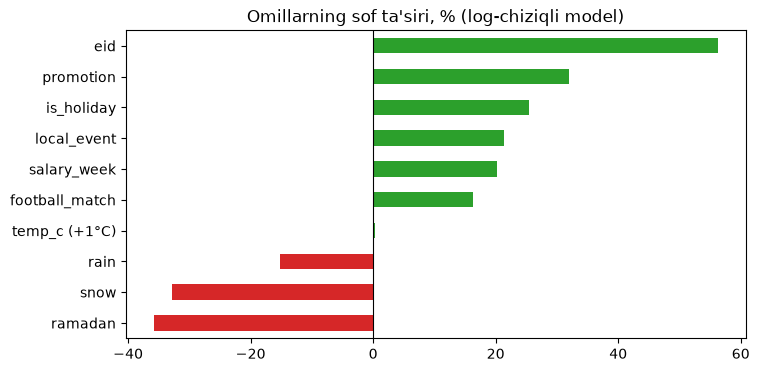

In [10]:
# Har bir omil mijozlar soniga necha % ta'sir qiladi (boshqa hamma narsa teng bo'lganda)
# is_weekend olinmaydi: u weekday ustunlari bilan to'liq takrorlanadi (multikollinearlik)
flags = ["eid", "promotion", "salary_week", "local_event", "football_match", "is_holiday",
         "rain", "snow", "ramadan"]
Xe = pd.get_dummies(df[flags + ["temp_c", "weekday", "month"]], columns=["weekday", "month"], drop_first=True)
effect_model = LinearRegression().fit(Xe, np.log(df.customers))
effect = pd.Series((np.exp(effect_model.coef_[:len(flags) + 1]) - 1) * 100, index=flags + ["temp_c (+1°C)"]).sort_values()

effect.plot(kind="barh", color=np.where(effect > 0, "tab:green", "tab:red"), figsize=(8, 4))
plt.title("Omillarning sof ta'siri, % (log-chiziqli model)"); plt.axvline(0, color="black", lw=0.8)
plt.show()

## Yakuniy xulosa

| Savol | Javob |
|---|---|
| Talabni nima belgilaydi? | Hafta kuni (juma/shanba ↑), hayit, aksiya, oylik haftasi, tadbirlar ↑; Ramazon, qor, yomg'ir ↓; iliq havo ↑ |
| Eng yaxshi model | **Ridge (log target)**, ~93% aniqlik, R² ≈ 0.92. Keras linear ham xuddi shunday natija beradi |
| Keras/TensorFlow | Ishlaydi, lekin 900 qatorli jadvalda Ridge'dan yaxshi emas. MLP esa biroz yomonroq |
| 95% aniqlik | **Yo'q.** Ma'lumotda ~8% tasodifiy shovqin bor. 98% faqat leakage bilan chiqadi va u soxta |
| Biznes uchun foyda | Ertangi mijozlar, guruch, salat va tushumni **95% ishonch oralig'i** bilan rejalashtirish |

**Amaliy tavsiyalar:**
- Guruch va salatni bashoratning **yuqori chegarasiga** yaqin tayyorlang: mahsulot yetmay qolishi ortib qolishidan qimmatroq tushadi.
- Aksiyalarni talab past kunlarga qo'ying (dushanba–seshanba, Ramazon, qishki oylar): bu kunlarda ular eng ko'p foyda beradi.
- Aniqlikni oshirish uchun model emas, **ma'lumot** to'plang: bronlar, buyurtmalar, tadbirlar tafsiloti.